In [1]:
# Run this cell to load the NumPy library and a plotting library
import numpy as np
import matplotlib.pyplot as plt

# Gelman and Rubin's "R Statistic"
Gelman and Rubin's "R statistic" is used to monitor convergence of a Markov chain "on the fly" or as it is running. To describe this statistic, we begin by reviewing a standard sample variance.

Let $X_{1}, X_{2}, \ldots, X_{n}$ be a sequence of independent and identically distributed ("iid") random variables from some underlying distribution with mean $\mu$ and variance $\sigma^{2}$. $\mu$ is a measure of location of the underlying distribution and $\sigma^{2}$ is a measure of how "spread out" the distribution is.

The <b>sample mean</b> is the average value
$$
\overline{X} = \frac{1}{n} \sum_{i=1}^{n} X_{i},
$$

which is often used as an estimator of the underlying distribution mean $\mu$. It is an <b>unbiased</b> estimator in the sense that the expected value of $\overline{X}$ is equal to $\mu$.

The <b>sample variance</b>, which we will call $S^{2}$, is often taken to be the average of the squared deviations of each $X_{i}$ from the sample mean $\overline{X}$:

$$
\frac{\sum_{i=1}^{n} (X_{i}-\overline{X})^{2}}{n}.
$$

However, this random quantity (before the sample is actually observed and we have numbers) is not expected to be exactly $\sigma^{2}$ when observed. That is, it is a <b>biased</b> estimator of $\sigma^{2}$. For this reason, an adjustment is typically made. We define the <b>sample variance</b> for $X_{1}, X_{2}, \ldots, X_{n}$ to be

$$
S^{2} = \frac{\sum_{i=1}^{n} (X_{i}-\overline{X})^{2}}{n-1}.
$$

Note that some people will define the sample variance in the first way with an $n$ in the denominator where we have the $n-1$.

By squaring the numerator in $S^{2}$, running the sum through, and collecting some terms, one could show that

$$
S^{2} = \frac{\sum_{i=1}^{n} X_{i}^{2} - (\sum_{i=1}^{n} X_{i})^{2}/n}{n-1}.
$$

In the next cell, we will use this expression to compute a sample variance for a given sample of size $10$.

In [2]:
# Run this cell
thesample = np.array([0.2, 1.7, -1.3, 5.2, 0.8, 0.5, 1.2, 0.4, 1.4, 2.8])

n = len(thesample)
(np.sum(thesample**2)-np.sum(thesample)**2/n)/(n-1)

3.034333333333333

There is also a built-in function in a statistics library in Python that will do this.

In [3]:
# Run this cell
import statistics as stat
stat.variance(thesample)

3.0343333333333335

<hr style="height:3px;border:none;color:#a64966;background-color:#a64966;">
<br>

Imagine now that, instead of looking simple "iid" copies of a variable from some distribution, we are looking at values of a Markov chain: $X_{0}, X_{1}, X_{2}, \ldots$. Indeed, we will look at several copies of the Markov chain so we will use double subscripts like this.

$$
\begin{array}{lcccc}
\mbox{Copy 1:} &X_{10}, &X_{11}, &X_{12}, &\ldots\\
\mbox{Copy 2:} &X_{20}, &X_{21}, &X_{22}, &\ldots\\
\mbox{Copy 3:} &X_{30}, &X_{31}, &X_{32}, &\ldots\\
\end{array}
$$

In general, we will run $m$ independent copies of the chain from various starting points out to time $n$. Ignoring the starting points, we will collect values

$$
X_{ij} \qquad \mbox{for} \,\,\, i=1,2,\ldots m, \,\,\,=1,2,\ldots, n
$$

This may, for example, represent $m$ different runs of a Metropolis-Hastings algorithm each going out to time $n$. The starting points should be chosen from many different regions of the state space.

If we let $\overline{X}_{i}$ be the sample mean for the ith sequence:
$$
\overline{X}_{i} = \frac{1}{n} \sum_{j=1}^{n} X_{ij},
$$

then the ith sequence has a sample variance
$$
S_{i}^{2} := \frac{\sum_{j=1}^{n} (X_{ij}-\overline{X}_{i})^{2}}{n-1}.
$$

Again, this is a sample variance from <i>within</i> one of the sequences. We will average these over all $m$ sequences or copies of our Markov chain to produce a statistic called the <font color="red"><i>within sequence sample variance</i></font>:

$$
W := \frac{1}{m} \sum_{i=1}^{m} S_{i}^{2}.
$$

<br>
<hr style="height:3px;border:none;color:#a64966;background-color:#a64966;">

<br>
Consider now the collection of sample path means $\overline{X}_{1}, \overline{X}_{2}, \overline{X}_{3}, \ldots$. 

(Note that a common notation here is to use a "dot" in the subsctipts like this $\overline{X}_{1 \cdot}, \overline{X}_{2 \cdot}, \overline{X}_{3 \cdot}, \ldots$ The "dot" represents the index that has been averaged over. We will not use this dot here for notational simplicity.)

Denote and define the <b>grand sample mean</b> as

$$
\overline{X} = \frac{1}{m} \sum_{i=1}^{m} \overline{X}_{i}
$$

(Note that it is common to denote this grand mean with a "double dot" subscript. Again, for simplicity, we will not use this notaton here!)

We may now define the <font color="red"><i>between sequence sample variance</i></font> by the sample variance of the sample means as follows:

$$
B := \frac{\sum_{i=1}^{m} (\overline{X}_{i} - \overline{X})^{2}}{m-1} 
$$

<br>
<hr style="height:3px;border:none;color:#a64966;background-color:#a64966;">

<br>
An MCMC algorithm is "targeting" a distribution that we have been calling $\pi$. That is, we are ultimately trying to obtain simulated values or "draws" from $\pi$. This distribution has it's own mean and variance. We will call this variance $V_{\pi}$. One can show that, if the $X_{ij}$ truly have the distribution $\pi$, then $W$ is an unbiased estimator of $V_{\pi}$ and

$$
\widehat{V_{\pi}} := \frac{n-1}{n} W + B
$$

is also an unbiased estimator of $V_{\pi}$.

Presumably, we are not starting our $m$ copies of a Markov chain with draws from $\pi$, as the entire point of most MCMC algorithms is to come up with a way to obtain approximate draws from $\pi$ in the limit. In general, if we start the $m$ chains with "widely scattered" or "overdispersed" points $X_{10}, X_{20}, X_{30}, \ldots$ then
<ul>
    <li>  $W$ will underestimate $V_{\pi}$, and</li>
    <li> $\widehat{V_\pi}$ will overestimate $V_{\pi}$.
</ul>    

However, as $n \rightarrow \infty$, one could show that
<ul>
    <li>  $W$ will approach $V_{\pi}$ from below, and</li>
    <li> $\widehat{V_\pi}$ will approach $V_{\pi}$ from above.
</ul>    

<br>
<hr style="height:3px;border:none;color:#a64966;background-color:#a64966;">

<br>
<b>Gelman and Rubin's R statistic</b> is defined as
$$
R = \frac{\widehat{V_{\pi}}}{W}.
$$

The quantity $\sqrt{R}$ is known as a <b>potential scale reduction factor</b>. It is an estimate of the factor by which the variance of the current
distribution will decrease in another iteration. 

The expected value of $R$ (and also $\sqrt{R}$) is greater than or equal to $1$. Both will approach $1$ from above as the copies of the Markov chain settle into the stationary/limiting distribution $\pi$ as $n$ gets large. It is possible that $R$ is less than $1$ due to sampling variability.

<br>
<hr style="height:3px;border:none;color:#a64966;background-color:#a64966;">

<br>
We will now run a Metropolis-Hastings algorithm to sample values from a target distribution with probability density function

$$
\pi(x) = \frac{2}{5} x^{2} (\sin x + 1) e^{-x} 
$$
for $x \geq 0$.

We will choose our transition candidate density $q(x,y)$ to be independent of the current value of the chain. That is, $q(x,y)$ will have the form $q(x,y) = q(y)$. In particular, to get some good cancellation, we will choose $q(y)$ to be proportional to

$$
y^{2} e^{-y}
$$
for $y \geq 0$. This is like a gamma pdf:

$$
f(x) = \frac{1}{\Gamma(\alpha)} \beta^{\alpha} x^{\alpha-1} e^{-\beta x}, \qquad \mbox{for} \,\,\, x \geq 0,
$$

with $\alpha = 3$ and $\beta = 1$. Matching constants, we see that the full form of $q$ is

$$
q(y) = \frac{1}{2} y^{2} e^{-y}.
$$

We have seen how to simulate values from this sort of $q(y)$ using the accept-reject algorithm. Here, for simplicity since simulation from $q$ is but one step in our larger Metropolis-Hastings algorithm, we will take advantage of a built-in gamma random variable generator in R. To obtain $n$ values from the gamma distribution with shape parameter $\alpha$ and inverse scale parameter $\beta=1$, we simply have to type <code>np.random.gamma(alpha,1,n)</code>. (For a more general value of $\beta$, we would type <code>np.random.gamma(alpha,1/beta,alpha)</code>. Recall that some people define the gamma pdf with $1/\beta$ in place of the $\beta$ in our parameterization. Python uses the alternate parameterization!)

<br>
<hr style="height:3px;border:none;color:#a64966;background-color:#a64966;">

<br>
In the next cell, we will first code a single Metropolis-Hasting chain. Note that, when the chain is at $x$ and a value of $y$ is proposed, the acceptance probability will be

$$
\alpha(x,y) = \min \left( 1, \frac{\pi(y) q(x)}{\pi(x) q(y)}\right) = \min \left( 1, \frac{\sin y + 1}{\sin x + 1}\right).
$$
<br>
Recall that, for $0 \leq U \leq 1$, checking whether $U \leq \alpha(x,y)$ is equivalent to checking whether $U \leq (\sin(y)+1)/(\sin(x)+1)$.

<br>

In [4]:
x = 2                                     # an arbitrary starting value
longtime = 1000

for i in range(longtime):
    y = np.random.gamma(3,1,1)            # propose a y-value
    ratio = (np.sin(y)+1)/(np.sin(x)+1)   # compute the MH-ratio
    u = np.random.rand()                  # generate a unif(0,1)
    if u <= ratio:
        x = y

We will now run 3 chains at once from the (rather arbitrarily chosen) starting values $0.2$, $2$, and $4.8$. The Gelman and Rubin R statistic assumes that we are running independent copies of the chains, so each will get its own $y$ and $u$ values.

In [5]:
x = np.array([0.2,2,4.8])
longtime = 1000

for i in range(longtime):
    y = np.random.gamma(3,1,3)            # propose 3 y-values
    ratio = (np.sin(y)+1)/(np.sin(x)+1)   # compute the 3 MH-ratios all at once ("ratio" will be 3-dimensional here)
    u = np.random.rand(3)                 # generate 3 unif(0,1)s
    x[u <= ratio] = y[u <=ratio]          # update each x component for which the corresponding u is less than or
                                          # equal to the corresponding ratio

In [6]:
# Here are the final points for each of the 3 chains after 1000 time steps
x

array([1.23819448, 1.4012414 , 1.25245297])

In order to compute the Gelman and Rubin R statistic, we will keep a running tally of $\sum X_{i}$ and $\sum X_{i}^{2}$ for each chain. We will call the first "sum_x" and "sum_xsq". (Note: Historically, it was a bad idea to use underscores in variable names in R as an underscore used to represent an assignment operator, but these days it is fine!) We will then compute

$$
S_{i}^{2} := \frac{\sum_{j=1}^{n} (X_{ij}-\overline{X}_{i})^{2}}{n-1} = \frac{\sum_{j=1}^{n} X_{ij}^{2} - (\sum_{j=1}^{n} X_{ij})^{2}/n}{n-1}. 
$$

Here, $n$ will actually be $i$ in our loop <font color="red">if we first adjust i to go from 1 to 1000</font> instead of 0 to 999. We can do this by replacing <code>for i in range(longtime)</code> to <code> for i in range(1,longtime+1)</code>. <font color="red">We will use ### in comments for newly added lines.</font>

In [7]:
x = np.array([0.2,2,4.8])
longtime = 1000

sum_x = np.zeros(3)                              ### initialize the 3 sums to be 0
sum_xsq = np.zeros(3)                            ### initialize the 3 sums of squares to be 0

for i in range(1,longtime+1):                    ### made a change here so that i goes from 1 to 1000
    y = np.random.gamma(3,1,3)                   # propose 3 y-values
    ratio = (np.sin(y)+1)/(np.sin(x)+1)          # compute the 3 MH-ratios all at once ("ratio" will be 3-dimensional here)
    u = np.random.rand(3)                        # generate 3 unif(0,1)s
    x[u <= ratio] = y[u <=ratio]                 # update each x component for which the corresponding u is less than or
                                                 # equal to the corresponding ratio
        
    sum_x = sum_x + x                            ### update the sum of the x's for each chain
    sum_xsq = sum_xsq + x**2                     ### update the sum of the x's squared for each chain
    variances = (sum_xsq-((sum_x)**2)/i)/(i-1)   ### compute the running sample variance

We will now add a line to the code to compute the within sequence variance ($W$) at each time step of the Metropolis-Hastings chain. This is a step in computing the Gelman-Rubin R statistic.

In [8]:
x = np.array([0.2,2,4.8])
longtime = 1000

sum_x = np.zeros(3)                              # initialize the 3 sums to be 0
sum_xsq = np.zeros(3)                            # initialize the 3 sums of squares to be 0

for i in range(1,longtime+1):
    n = i+1                                      # define time step since loop starts with i=0
    y = np.random.gamma(3,1,3)                   # propose 3 y-values
    ratio = (np.sin(y)+1)/(np.sin(x)+1)          # compute the 3 MH-ratios all at once ("ratio" will be 3-dimensional here)
    u = np.random.rand(3)                        # generate 3 unif(0,1)s
    x[u <= ratio] = y[u <=ratio]                 # update each x component for which the corresponding u is less than or
                                                 # equal to the corresponding ratio
        
    sum_x = sum_x + x                            # update the sum of the x's for each chain
    sum_xsq = sum_xsq + x**2                     # update the sum of the x's squared for each chain
    variances = (sum_xsq-((sum_x)**2)/i)/(i-1)   # compute the running sample variance
    W = sum(variances)/3                         ### compute W, could use "np.mean(variances)" here

We now add lines to the code to compute the between sequence variance $B$ and the final Gelman-Rubin R statistic. 

In [9]:
x = np.array([0.2,2,4.8])
longtime = 1000

sum_x = np.zeros(3)                              # initialize the 3 sums to be 0
sum_xsq = np.zeros(3)                            # initialize the 3 sums of squares to be 0

for i in range(1,longtime+1):
    y = np.random.gamma(3,1,3)                   # propose 3 y-values
    ratio = (np.sin(y)+1)/(np.sin(x)+1)          # compute the 3 MH-ratios all at once ("ratio" will be 3-dimensional here)
    u = np.random.rand(3)                        # generate 3 unif(0,1)s
    x[u <= ratio] = y[u <=ratio]                 # update each x component for which the corresponding u is less than or
                                                 # equal to the corresponding ratio
        
    sum_x = sum_x + x                            # update the sum of the x's for each chain
    sum_xsq = sum_xsq + x**2                     # update the sum of the x's squared for each chain
    variances = (sum_xsq-((sum_x)**2)/i)/(i-1)   # compute the running sample variance
    W = sum(variances)/3                         # compute W, could use "np.mean(variances)" here
    
    the_means = sum_x/i                          ### individual chain running mean
    grand_mean = sum(the_means)/3                ### grand mean, could use "np.mean(the_means)"" here
    B = sum((the_means-grand_mean)**2)/(3-1)     ### compute B

Finally, we will compute $\widehat{V_{\pi}}$ and the Gelman-Rubin statistic $R$. <font color="red"> Normally, we do not store values of R, but instead just observe it at each time step to see if it is close to 1. Here, we will store values of R for the purpose of making a plot to show its evolution.</font>

In [10]:
x = np.array([0.2,2,4.8])
longtime = 1000
R = np.zeros(longtime)                           ### initialize a vector to hold values of B

sum_x = np.zeros(3)                              # initialize the 3 sums to be 0
sum_xsq = np.zeros(3)                            # initialize the 3 sums of squares to be 0

for i in range(1,longtime+1):
    y = np.random.gamma(3,1,3)                   # propose 3 y-values
    ratio = (np.sin(y)+1)/(np.sin(x)+1)          # compute the 3 MH-ratios all at once ("ratio" will be 3-dimensional here)
    u = np.random.rand(3)                        # generate 3 unif(0,1)s
    x[u <= ratio] = y[u <=ratio]                 # update each x component for which the corresponding u is less than or
                                                 # equal to the corresponding ratio
        
    sum_x = sum_x + x                            # update the sum of the x's for each chain
    sum_xsq = sum_xsq + x**2                     # update the sum of the x's squared for each chain
    variances = (sum_xsq-((sum_x)**2)/i)/(i-1)   # compute the running sample variance
    W = sum(variances)/3                         # compute W, could use "np.mean(variances)" here
    
    the_means = sum_x/i                          ### individual chain running mean
    grand_mean = sum(the_means)/3                ### grand mean, could use "np.mean(the_means)"" here
    B = sum((the_means-grand_mean)**2)/(3-1)     ### compute B
    
    V = ((i-1)/i)*W + B                          ### compute V hat sub pi
    R[i-1] = V/W                                 ### Store R with zero-based indexing

We now have a vector of evolving 𝑅 values. The first element will be an "nan" because, when computing 𝑊, we have divided by 𝑖−1=1−1=0 when we computed a sample variance for a sample of size 1. The sample variance for a sample of size 1 should be zero because there is no variability in a sample like that. Our "nan" is an artifact of us using the unbiased version of sample variance where we divide by the number of terms in the sample minus 1. All of that said, it is an uninteresting data point and we will simply drop the first 𝑅 value.


In [11]:
# Run this cell to drop the first (the "zeroth") R value from the vector of R values
R = np.delete(R,0)

We will now plot the consecutive R values. Remember, we want to see the values approaching $1$. Once this happens, we have some evidence that the Metropolis-Hastings chain is settling into its stationary distribution. 

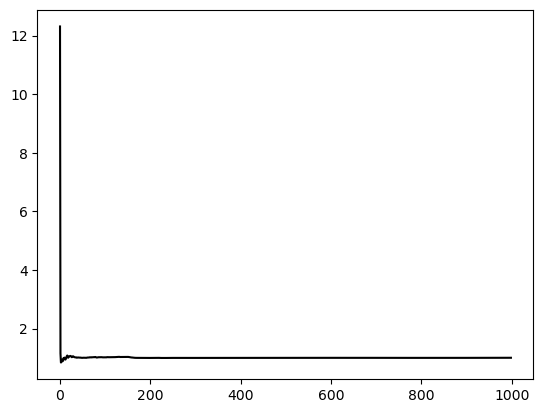

In [12]:
plt.plot(R,color='black')  # Create the plot using the command "plot" from the library we have named "plt"
plt.show()                 # Show the plot (Your plot will show without this but
                           # it is a good habit to get into for the ultimate display 
                           # of more complex plots and you will get a nicer looking
                           # plot even here!)                

This algorithm uses randomness. Your first values of R may be quite large for one run of this notebook and not so large for another run. It will be difficult to see what is going on in the plot for a rapid drop-off of large R values to small. In the next cell, we will only plot the R values for time steps 10 through 1000 using the zero-based indexing of 9 thorugh 999. You might change the starting index until you can really see what is going on. (For us, time steps 10 through 1000 gave a nice view of things but this may be different for your run of the algorithm.) We will also add a line at height 1.

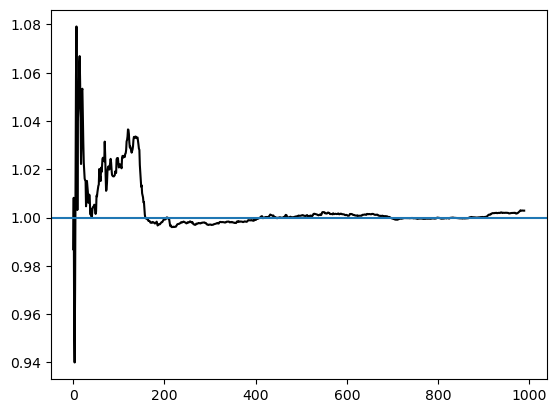

In [13]:
plt.plot(R[9:999],color='black')  # Create the plot using the command "plot" from the library we have named "plt"
plt.axhline(y=1)
plt.show()                 # Show the plot (Your plot will show without this but
                           # it is a good habit to get into for the ultimate display 
                           # of more complex plots and you will get a nicer looking
                           # plot even here!)     

Values of $R$ that are greater than $1.1$ are generally interpreted as showing a lack of convergence. We prefer to see $R < 1.01$ before feeling comfortable enough to say that convergence is achieved. Again, it is possible to see values of $R$ that are less than $1$ due to sampling variability and choices of starting values for the chains that are too close to each other. (The recommendation is that these values be "overdispersed" or "spread out" with respect to the target distribution. This means that they should  have more variability than values that might be sampled from the target distribution.)

In the next cell, we find the indices of the elements in the R vector for which $R < 1.01$. While we may see some early on, we are looking for $R$ to stay consistently below $1.01$. For one of our runs of this notebook, we determined that we need to run the Metropolis-Hastings algorithm out 185 time steps before collecting output. Due to the randomness involved, you will see something different!

In [14]:
np.where(R<1.01)

(array([  2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,  18,
         37,  38,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
         53,  54,  55,  56,  57,  58,  59,  60,  61, 161, 162, 163, 164,
        165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177,
        178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190,
        191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203,
        204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216,
        217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229,
        230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242,
        243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255,
        256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268,
        269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281,
        282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294,
        295, 296, 297, 298, 299, 300, 301, 302, 303

To finish, we are going to run 100,000 single independent Metropolis-Hastings chains, each for the number of time steps that you have selected by looking at the results of the previous cell. 

In [15]:
# Run this cell. Change the 185 based on your results in the previous cell
longtime = 185

In [16]:
# Run this cell-- be patient!
# The Metropolis-Hastings Algorithm
reps = 100000
mysample = np.zeros(reps)

for j in range(reps):
    x = 2
    for i in range(longtime):
        y = np.random.gamma(3,1,1)            # propose a y-value
        ratio = (np.sin(y)+1)/(np.sin(x)+1)   # compute the MH-ratio
        u = np.random.rand()                  # generate a unif(0,1)
        if u <= ratio:
            x = y
        
    mysample[j] = x      

In the next cell, we will make a histogram of the results and superimpose the target pdf. We have chosen a histogram bin width of $0.5$ based on the range of values observed in "mysample" from our own runs of the Metropolis-Hasting algorithm. Normally, you would decide the bin width by some trial and error. A bin width that is too large will result in a loss of detail in the shape of the histogram while a bin width that is too small will result in a very "spikey" result with artificially empty bins between bins containing observations. Feel free to experiment with your own bin widths!

In [17]:
max(mysample)

15.962458143894253

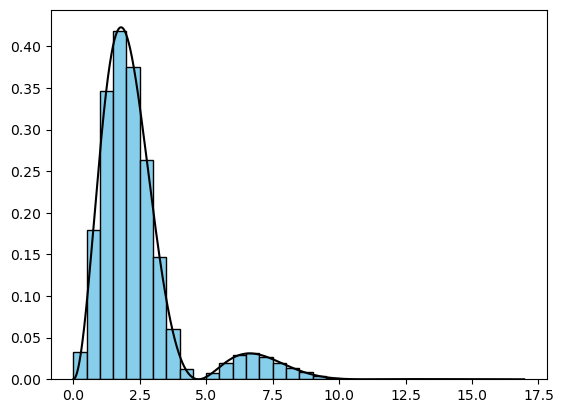

In [18]:
# Make a histogram of results
m = max(mysample) + 1                               # upper bound for sequence of bin width breaks
br = np.arange(0.0, m, 0.5)                         # create sequence of bin breaks with widths 0.5  

# make a histogram, density = 'True' ensures that the y-axis is for density and not counts
plt.hist(mysample, bins=br, color='skyblue', edgecolor='black', density='True')

# for superimposed curve
x = np.linspace(0, m, 1000)                        # Create a sequence of 1000 equally-spaced values between 0 and m
f = (2/5)*(x**2)*(np.sin(x)+1)*np.exp(-x)          # the y-values for the superimposed pdf
plt.plot(x,f,color='black')                        # superimpose the target pdf

plt.show()

We think it looks great! If you do not, you might re-run your Metropolis-Hastings algorithm with a larger value for "longtime". Gelman and Rubin's R-statistic is not foolproof but is better than nothing, especially in the case where we don't have a closed-form expression for the target pdf that we can compare to a histogram. It is also useful for higher-dimensional distributions where graphical visualizations are difficult. In this case, one would monitor an R-statistic for each component of the chain.